# Chương 4. Dự đoán giá đóng cửa cổ phiếu bằng RNN, LSTM và GRU

Notebook dự đoán **Close của phiên giao dịch kế tiếp** từ 60 phiên trước đó. Dữ liệu chứng khoán là chuỗi thời gian: mỗi phiên có giá Open, High, Low, Close và Volume; thứ tự thời gian quyết định ý nghĩa của đầu vào. Mỗi mẫu có `X` là 60 phiên đã biết và `y` là Close của phiên thứ 61.

Ba mô hình PyTorch được huấn luyện và so sánh trong cùng điều kiện. Dữ liệu chính là [S&P 500 Stock Data của Cam Nugent trên Kaggle](https://www.kaggle.com/datasets/camnugent/sandp500), file `all_stocks_5yr.csv`. Đây là dữ liệu lịch sử **2013–2018**; dự báo cuối notebook chỉ minh họa phiên kế tiếp sau ngày cuối dataset, không phải giá cổ phiếu hiện tại.

> Chạy lần lượt từ trên xuống dưới. Đặt `data/all_stocks_5yr.csv` cạnh notebook hoặc sửa `DATA_PATH` ở ô cấu hình.

---
## 01. Thư viện và cấu hình

Giữ cách đặt cấu hình tập trung như notebook dự đoán giá vàng. `STOCK_SYMBOL = "AAPL"` có thể đổi sang `MSFT`, `GOOGL` hoặc `AMZN` rồi chạy lại toàn bộ notebook. Seed giúp kết quả dễ lặp lại; CPU và GPU vẫn có thể sai khác nhỏ.

In [1]:
from pathlib import Path
import copy
import random
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from torch import nn
from torch.utils.data import Dataset, DataLoader

DATA_PATH = Path("data/all_stocks_5yr.csv")
ARTIFACT_DIR = Path("artifacts")
STOCK_SYMBOL = "AAPL"
FEATURES = ["open", "high", "low", "close", "volume"]
SEQUENCE_LENGTH = 60
BATCH_SIZE = 64
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.001
MAX_EPOCHS = 50
PATIENCE = 8
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị: {device} | Mã cổ phiếu: {STOCK_SYMBOL} | Cửa sổ: {SEQUENCE_LENGTH} phiên")

Thiết bị: cpu | Mã cổ phiếu: AAPL | Cửa sổ: 60 phiên


---
## 02. Đọc dataset

CSV được tải từ Kaggle vào thư mục `data/`. Ô này cho biết kích thước, tên cột, năm dòng đầu, số mã và một số mã mẫu. Nếu chuyển notebook sang máy khác, tải dataset bằng đường dẫn nguồn ở đầu notebook và đặt file tại `DATA_PATH`.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_PATH}. Tải all_stocks_5yr.csv từ "
        "https://www.kaggle.com/datasets/camnugent/sandp500 và đặt vào data/."
    )

raw = pd.read_csv(DATA_PATH)
required_columns = {"date", "open", "high", "low", "close", "volume", "Name"}
if not required_columns.issubset(raw.columns):
    raise ValueError(f"CSV thiếu cột: {sorted(required_columns - set(raw.columns))}")

symbols = sorted(raw["Name"].dropna().astype(str).unique())
print(f"Kích thước dataset: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
print(f"Các cột: {list(raw.columns)}")
print(f"Số mã cổ phiếu: {len(symbols)}")
print(f"Một số mã: {symbols[:20]}")
display(raw.head())

Kích thước dataset: 619,040 dòng × 7 cột
Các cột: ['date', 'open', 'high', 'low', 'close', 'volume', 'Name']
Số mã cổ phiếu: 505
Một số mã: ['A', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADS', 'ADSK', 'AEE', 'AEP', 'AES', 'AET', 'AFL', 'AGN']


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


---
## 03. Lọc mã và làm sạch dữ liệu

Chỉ dùng một mã tại mỗi lần chạy. Chuyển ngày, giá và khối lượng về kiểu phù hợp; kiểm tra giá trị thiếu và ngày trùng; bỏ bản ghi thiếu hoặc giá/khối lượng không hợp lệ. Nếu một ngày trùng, giữ bản ghi cuối cùng sau khi sắp xếp ổn định. Dữ liệu sau làm sạch luôn theo ngày tăng dần.

In [3]:
if STOCK_SYMBOL not in symbols:
    raise ValueError(f"Không có mã {STOCK_SYMBOL}. Hãy chọn một mã trong danh sách ở trên.")

stock = raw.loc[raw["Name"] == STOCK_SYMBOL].copy()
stock["date"] = pd.to_datetime(stock["date"], errors="coerce")
for column in FEATURES:
    stock[column] = pd.to_numeric(stock[column], errors="coerce")

print(f"Mã: {STOCK_SYMBOL} | số phiên ban đầu: {len(stock):,}")
display(pd.DataFrame({"Số giá trị thiếu": stock[["date", *FEATURES]].isna().sum()}))
print(f"Dòng trùng hoàn toàn: {stock.duplicated().sum()}")
print(f"Ngày trùng: {stock.duplicated(subset='date').sum()}")

stock = stock.dropna(subset=["date", *FEATURES])
stock = stock.loc[(stock[["open", "high", "low", "close"]] > 0).all(axis=1) & (stock["volume"] >= 0)]
stock = stock.sort_values("date", kind="stable").drop_duplicates(subset="date", keep="last").reset_index(drop=True)
if len(stock) <= SEQUENCE_LENGTH + 20:
    raise ValueError("Không đủ phiên hợp lệ để tạo cửa sổ và chia train/validation/test.")

print(f"Còn lại: {len(stock):,} phiên | từ {stock['date'].min():%d/%m/%Y} đến {stock['date'].max():%d/%m/%Y}")
display(stock.head())

Mã: AAPL | số phiên ban đầu: 1,259


,Số giá trị thiếu
date,0
open,0
high,0
low,0
close,0
volume,0


Dòng trùng hoàn toàn: 0
Ngày trùng: 0
Còn lại: 1,259 phiên | từ 08/02/2013 đến 07/02/2018


,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


---
## 04. Khám phá dữ liệu (EDA)

Xem thống kê OHLCV, xu hướng Close, Open so với Close, Volume, High so với Low và phân bố lợi suất ngày. `Return = Close.pct_change()` chỉ dùng để mô tả, không làm feature. Biểu đồ của toàn chuỗi là EDA; chúng không tham gia quá trình fit scaler hoặc huấn luyện.

,count,mean,std,min,25%,50%,75%,max
open,1259.0,109.06,30.55,55.42,84.65,108.97,127.34,1.793700e+02
high,1259.0,109.95,30.69,57.09,85.33,110.03,128.10,1.801000e+02
low,1259.0,108.14,30.38,55.01,84.25,108.05,126.29,1.782500e+02
close,1259.0,109.07,30.56,55.79,84.83,109.01,127.12,1.792600e+02
volume,1259.0,54047899.74,33468353.34,11475922.00,29694376.50,45668931.00,68708720.00,2.668336e+08


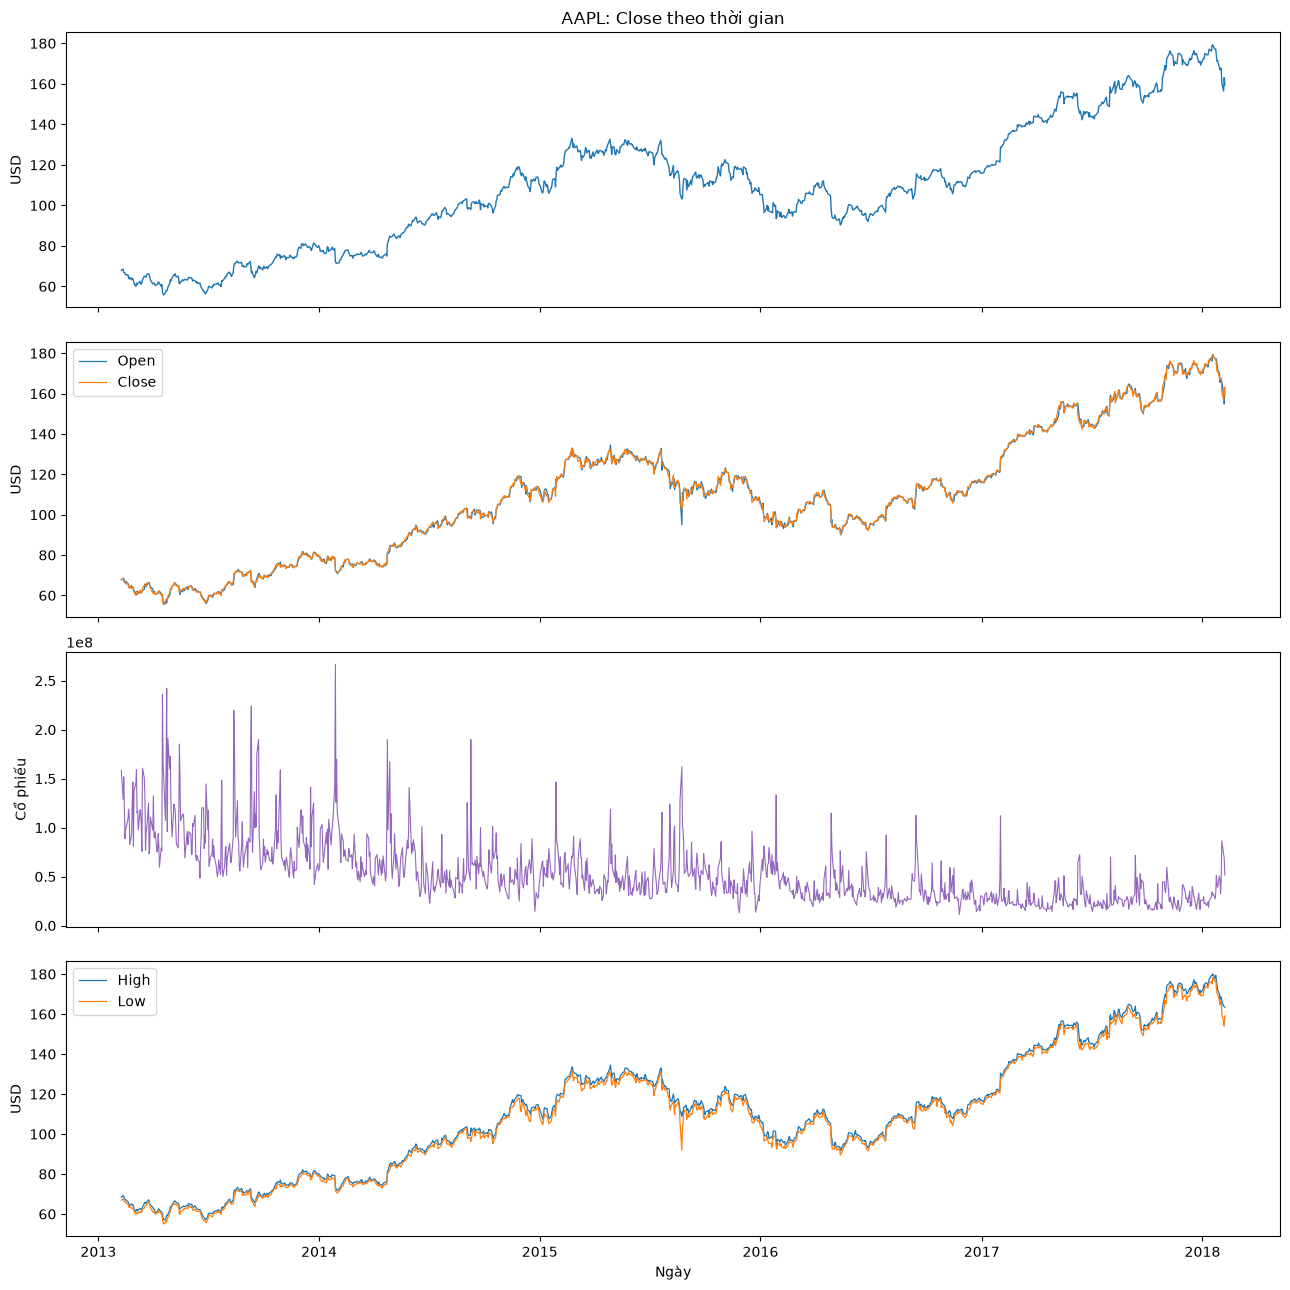

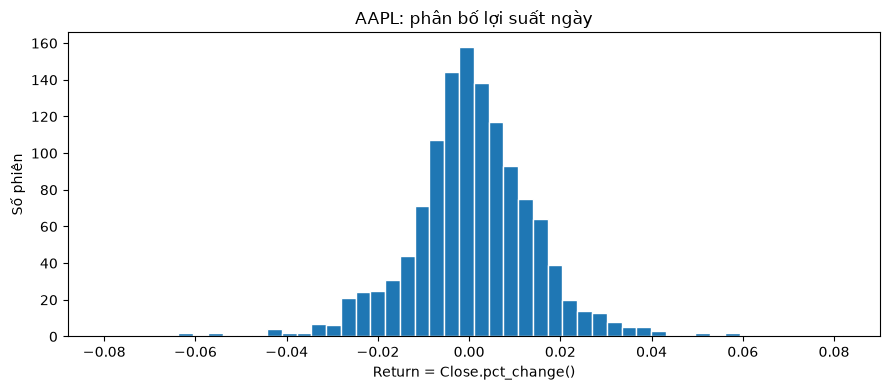

In [4]:
display(stock[FEATURES].describe().T.round(2))
stock["Return"] = stock["close"].pct_change()

fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)
axes[0].plot(stock["date"], stock["close"], color="tab:blue", linewidth=1)
axes[0].set(title=f"{STOCK_SYMBOL}: Close theo thời gian", ylabel="USD")
axes[1].plot(stock["date"], stock["open"], label="Open", linewidth=0.9)
axes[1].plot(stock["date"], stock["close"], label="Close", linewidth=0.9)
axes[1].set(ylabel="USD")
axes[1].legend()
axes[2].plot(stock["date"], stock["volume"], color="tab:purple", linewidth=0.8)
axes[2].set(ylabel="Cổ phiếu")
axes[3].plot(stock["date"], stock["high"], label="High", linewidth=0.9)
axes[3].plot(stock["date"], stock["low"], label="Low", linewidth=0.9)
axes[3].set(xlabel="Ngày", ylabel="USD")
axes[3].legend()
fig.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.hist(stock["Return"].dropna(), bins=50, color="tab:blue", edgecolor="white")
plt.title(f"{STOCK_SYMBOL}: phân bố lợi suất ngày")
plt.xlabel("Return = Close.pct_change()")
plt.ylabel("Số phiên")
plt.tight_layout()
plt.show()

**Nhận xét EDA.** Giá Close và Volume có thể thay đổi theo giai đoạn; lợi suất ngày thường tập trung quanh 0 nhưng vẫn có phiên biến động mạnh. Quan sát này chỉ mô tả chuỗi lịch sử. Khả năng dự đoán cần được đánh giá trên tập test ở các mục sau.

---
## 05. Feature, target và chia tập theo thời gian

Feature gồm `open`, `high`, `low`, `close`, `volume`. Không tạo chỉ báo dùng dữ liệu tương lai. Ngày đích được chia theo thứ tự thời gian: 70% train, 15% validation, 15% test. Cửa sổ đầu của validation/test được phép dùng các phiên ngay trước ranh giới làm ngữ cảnh, vì các phiên ấy đã xảy ra trước ngày cần dự đoán.

,Tập,Số ngày đích,Từ ngày,Đến ngày
0,Train,821,2013-05-07,2016-08-08
1,Validation,189,2016-08-09,2017-05-09
2,Test,189,2017-05-10,2018-02-07


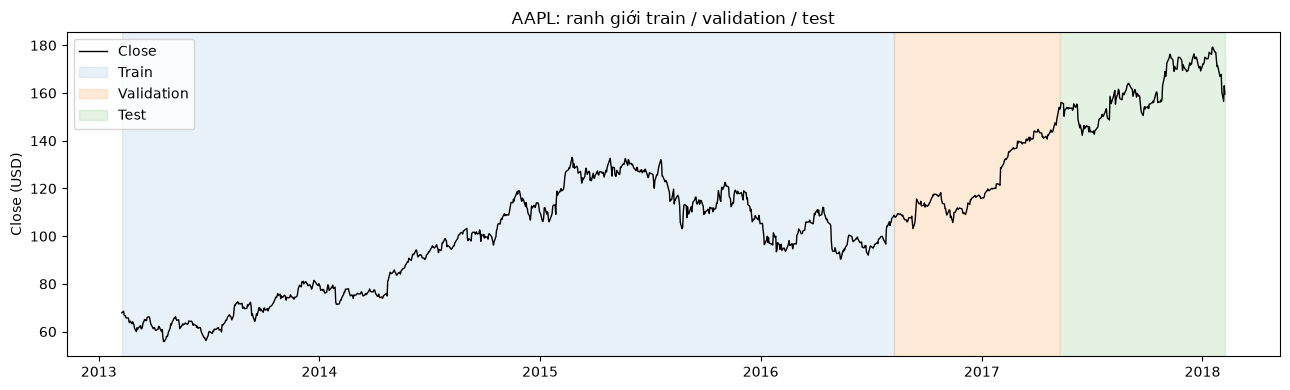

In [5]:
n_rows = len(stock)
train_end = int(n_rows * 0.70)
val_end = int(n_rows * 0.85)
if train_end <= SEQUENCE_LENGTH or val_end <= train_end or val_end >= n_rows:
    raise ValueError("Không đủ dữ liệu để chia 70/15/15 với cửa sổ hiện tại.")

split_info = pd.DataFrame({
    "Tập": ["Train", "Validation", "Test"],
    "Số ngày đích": [train_end - SEQUENCE_LENGTH, val_end - train_end, n_rows - val_end],
    "Từ ngày": [stock.loc[SEQUENCE_LENGTH, "date"], stock.loc[train_end, "date"], stock.loc[val_end, "date"]],
    "Đến ngày": [stock.loc[train_end - 1, "date"], stock.loc[val_end - 1, "date"], stock.loc[n_rows - 1, "date"]],
})
display(split_info)

plt.figure(figsize=(13, 4))
plt.plot(stock["date"], stock["close"], linewidth=1, color="black", label="Close")
plt.axvspan(stock.loc[0, "date"], stock.loc[train_end - 1, "date"], color="tab:blue", alpha=0.10, label="Train")
plt.axvspan(stock.loc[train_end, "date"], stock.loc[val_end - 1, "date"], color="tab:orange", alpha=0.16, label="Validation")
plt.axvspan(stock.loc[val_end, "date"], stock.loc[n_rows - 1, "date"], color="tab:green", alpha=0.13, label="Test")
plt.title(f"{STOCK_SYMBOL}: ranh giới train / validation / test")
plt.ylabel("Close (USD)")
plt.legend()
plt.tight_layout()
plt.show()

---
## 06. Chuẩn hóa trên train

Dùng hai `MinMaxScaler`: một cho 5 feature, một cho target `close`. Cả hai chỉ `fit` trên các dòng train; validation và test chỉ được `transform`. Scaler target riêng giúp hoàn nguyên dự đoán từ dạng `[n, 1]` về USD đúng cách.

In [6]:
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()
feature_scaler.fit(stock.loc[:train_end - 1, FEATURES])
target_scaler.fit(stock.loc[:train_end - 1, ["close"]])

features_scaled = feature_scaler.transform(stock[FEATURES]).astype(np.float32)
target_scaled = target_scaler.transform(stock[["close"]]).astype(np.float32)
display(pd.DataFrame({
    "Feature": FEATURES,
    "Min train": feature_scaler.data_min_,
    "Max train": feature_scaler.data_max_,
}).round(2))
print(f"Shape feature đã chuẩn hóa: {features_scaled.shape}; target: {target_scaled.shape}")

,Feature,Min train,Max train
0,open,55.42,1.344600e+02
1,high,57.09,1.345400e+02
2,low,55.01,1.314000e+02
3,close,55.79,1.330000e+02
4,volume,13046445.00,2.668336e+08


Shape feature đã chuẩn hóa: (1259, 5); target: (1259, 1)


---
## 07. Tạo cửa sổ trượt

`create_sequences()` lấy 60 hàng feature ngay trước ngày đích, rồi lấy Close của ngày đích làm nhãn. Chẳng hạn ngày `t-59 ... t` dùng để dự đoán Close ngày `t+1`. Sau khi tạo cửa sổ, gán mỗi mẫu vào tập theo **ngày đích**, không xáo trộn ngày.

In [7]:
def create_sequences(features, targets, sequence_length):
    X, y = [], []
    for target_day in range(sequence_length, len(features)):
        X.append(features[target_day - sequence_length:target_day])
        y.append(targets[target_day])
    return np.stack(X).astype(np.float32), np.asarray(y, dtype=np.float32).reshape(-1, 1)


X_all, y_all = create_sequences(features_scaled, target_scaled, SEQUENCE_LENGTH)
target_days = np.arange(SEQUENCE_LENGTH, n_rows)
train_mask = target_days < train_end
val_mask = (target_days >= train_end) & (target_days < val_end)
test_mask = target_days >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
test_dates = stock.loc[target_days[test_mask], "date"].reset_index(drop=True)

display(pd.DataFrame({
    "Tập": ["Train", "Validation", "Test"],
    "Shape X": [str(x.shape) for x in (X_train, X_val, X_test)],
    "Shape y": [str(y.shape) for y in (y_train, y_val, y_test)],
}))
print(f"Mỗi X: [60 phiên, {len(FEATURES)} feature]; mỗi y: [1 giá Close]")

,Tập,Shape X,Shape y
0,Train,"(821, 60, 5)","(821, 1)"
1,Validation,"(189, 60, 5)","(189, 1)"
2,Test,"(189, 60, 5)","(189, 1)"


Mỗi X: [60 phiên, 5 feature]; mỗi y: [1 giá Close]


---
## 08. PyTorch Dataset và DataLoader

Mỗi batch đầu vào có shape `[batch_size, 60, 5]`, nhãn có shape `[batch_size, 1]`. Các DataLoader giữ thứ tự thời gian (`shuffle=False`) để dễ theo dõi kết quả và ngày dự đoán.

In [8]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


train_loader = DataLoader(TimeSeriesDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(TimeSeriesDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TimeSeriesDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)
batch_X, batch_y = next(iter(train_loader))
print(f"Một batch: X = {tuple(batch_X.shape)}, y = {tuple(batch_y.shape)}")

Một batch: X = (64, 60, 5), y = (64, 1)


---
## 09. SimpleRNN

`nn.RNN` xử lý lần lượt 60 bước thời gian. Trạng thái của bước cuối có shape `[batch_size, 64]` và đi qua lớp Linear để cho ra một giá Close đã chuẩn hóa.

In [9]:
class SimpleRNN(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, output_size=1):
        super().__init__()
        self.recurrent = nn.RNN(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x: [batch, 60, 5]; trạng thái cuối: [batch, 64].
        states, _ = self.recurrent(x)
        return self.output(states[:, -1, :])  # [batch, 1]

---
## 10. LSTM

`nn.LSTM` có trạng thái ô nhớ và các cổng. Số tầng, hidden size, dropout và đầu ra tương đương SimpleRNN để so sánh trên cùng bài toán.

In [10]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, output_size=1):
        super().__init__()
        self.recurrent = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x: [batch, 60, 5]; dự đoán: [batch, 1].
        states, _ = self.recurrent(x)
        return self.output(states[:, -1, :])

---
## 11. GRU

`nn.GRU` cũng dùng cơ chế cổng, với trạng thái gọn hơn LSTM. Cấu hình được giữ giống hai mô hình trên.

In [11]:
class GRU(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2, output_size=1):
        super().__init__()
        self.recurrent = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x: [batch, 60, 5]; dự đoán: [batch, 1].
        states, _ = self.recurrent(x)
        return self.output(states[:, -1, :])

---
## 12. Hàm huấn luyện chung

Cả ba mô hình dùng MSELoss, Adam với learning rate 0.001, tối đa 50 epoch và early stopping với patience 8. Trọng số tốt nhất được chọn bằng validation loss rồi phục hồi sau khi dừng. Tập test không đi vào hàm huấn luyện.

In [12]:
def train_model(model, train_loader, val_loader, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train": [], "val": []}
    best_loss = float("inf")
    best_state = None
    waiting = 0

    for epoch in range(max_epochs):
        model.train()
        train_sum = 0.0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()
            train_sum += loss.item() * len(batch_X)
        train_loss = train_sum / len(train_loader.dataset)

        model.eval()
        val_sum = 0.0
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                val_sum += criterion(model(batch_X), batch_y).item() * len(batch_X)
        val_loss = val_sum / len(val_loader.dataset)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            waiting = 0
        else:
            waiting += 1
            if waiting >= patience:
                break

    model.load_state_dict(best_state)
    return model, history

---
## 13. Huấn luyện ba mô hình

SimpleRNN, LSTM và GRU dùng cùng train/validation, số tầng, hidden size, dropout, optimizer, learning rate và giới hạn epoch. Thời gian huấn luyện được đo riêng cho từng mô hình.

In [13]:
model_classes = {"SimpleRNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}
models, histories, training_times, training_rows = {}, {}, {}, []
for name, model_class in model_classes.items():
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = model_class(len(FEATURES), HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    start_time = time.perf_counter()
    models[name], histories[name] = train_model(model, train_loader, val_loader)
    training_times[name] = time.perf_counter() - start_time
    history = histories[name]
    training_rows.append({
        "Model": name,
        "Epoch tốt nhất": int(np.argmin(history["val"])) + 1,
        "Epoch đã chạy": len(history["val"]),
        "Validation MSE chuẩn hóa": min(history["val"]),
        "Training Time (s)": training_times[name],
    })
    print(f"{name}: {len(history['val'])} epoch, {training_times[name]:.1f} giây")
display(pd.DataFrame(training_rows).round(4))

SimpleRNN: 29 epoch, 6.1 giây


LSTM: 20 epoch, 4.0 giây


GRU: 15 epoch, 6.4 giây


,Model,Epoch tốt nhất,Epoch đã chạy,Validation MSE chuẩn hóa,Training Time (s)
0,SimpleRNN,21,29,0.0012,6.0999
1,LSTM,12,20,0.0011,4.0271
2,GRU,7,15,0.0012,6.4267


---
## 14. Biểu đồ loss

Mỗi ô hiển thị train loss và validation loss. Khoảng cách kéo dài giữa hai đường có thể gợi ý overfitting; chỉ số này cần đọc cùng biểu đồ dự đoán và metric.

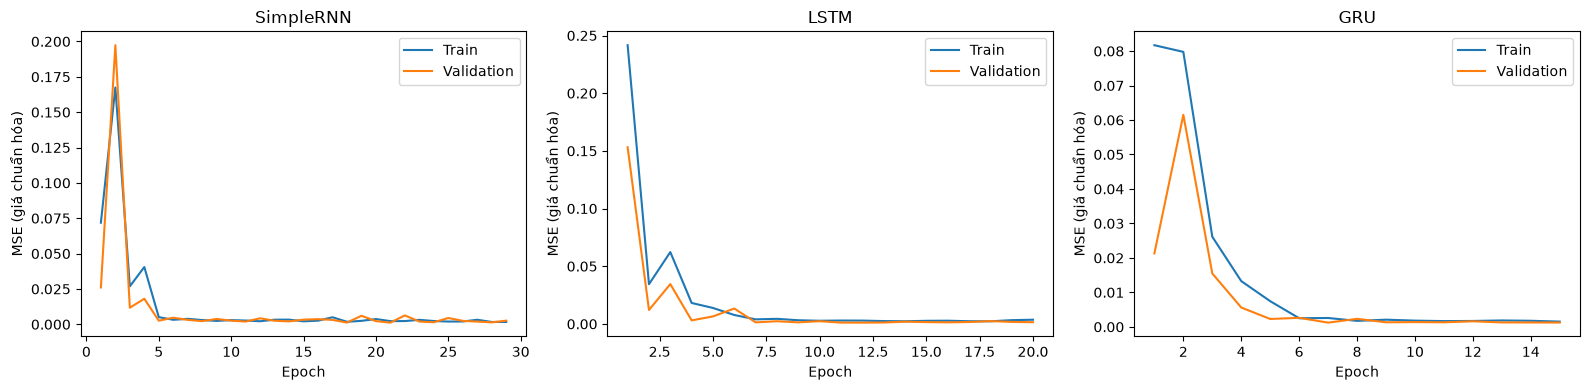

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, history) in zip(axes, histories.items()):
    epochs = np.arange(1, len(history["train"]) + 1)
    ax.plot(epochs, history["train"], label="Train")
    ax.plot(epochs, history["val"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="MSE (giá chuẩn hóa)")
    ax.legend()
fig.tight_layout()
plt.show()

---
## 15. Dự đoán trên test và hoàn nguyên đơn vị

Sau khi các mô hình đã được chọn epoch bằng validation, chạy dự đoán trên test đúng một lượt. Scaler target được fit riêng cho Close nên `inverse_transform()` nhận đúng shape `[số mẫu, 1]`, trả kết quả bằng USD.

In [15]:
def predict_scaled(model, loader):
    model.eval()
    chunks = []
    with torch.no_grad():
        for batch_X, _ in loader:
            chunks.append(model(batch_X.to(device)).cpu().numpy())
    return np.vstack(chunks)


y_actual = target_scaler.inverse_transform(y_test).ravel()
predictions = {}
for name, model in models.items():
    pred_scaled = predict_scaled(model, test_loader)
    predictions[name] = target_scaler.inverse_transform(pred_scaled).ravel()
print(f"Số dự đoán test: {len(y_actual)} | khoảng ngày: {test_dates.min():%d/%m/%Y}–{test_dates.max():%d/%m/%Y}")

Số dự đoán test: 189 | khoảng ngày: 10/05/2017–07/02/2018


---
## 16. Metrics và so sánh mô hình

MAE, MSE, RMSE đo sai số trên thang USD; R² không có đơn vị; MAPE là phần trăm và chỉ dùng các ngày có Close khác 0. Bảng được xếp theo RMSE thấp nhất trên test. Test không được dùng để fit scaler, cập nhật trọng số hoặc chọn epoch; việc chọn mô hình thắng cuộc trên test chỉ phục vụ so sánh minh họa.

In [16]:
metric_rows = []
nonzero = y_actual != 0
for name, y_pred in predictions.items():
    mse = mean_squared_error(y_actual, y_pred)
    metric_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_actual, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_actual, y_pred),
        "MAPE (%)": np.mean(np.abs((y_actual[nonzero] - y_pred[nonzero]) / y_actual[nonzero])) * 100,
        "Training Time (s)": training_times[name],
    })
results = pd.DataFrame(metric_rows).sort_values("RMSE").reset_index(drop=True)
best_name = str(results.loc[0, "Model"])
best_model = models[best_name]
display(results.round(3))

,Model,MAE,MSE,RMSE,R2,MAPE (%),Training Time (s)
0,GRU,5.179,38.089,6.172,0.620,3.137,6.427
1,LSTM,5.456,44.563,6.676,0.555,3.293,4.027
2,SimpleRNN,7.353,73.639,8.581,0.265,4.439,6.100


---
## 17. Actual vs Predicted

Ba biểu đồ riêng cho từng mô hình trên toàn test. Biểu đồ cuối phóng to tối đa 150 phiên test cuối để nhìn rõ sự khác biệt.

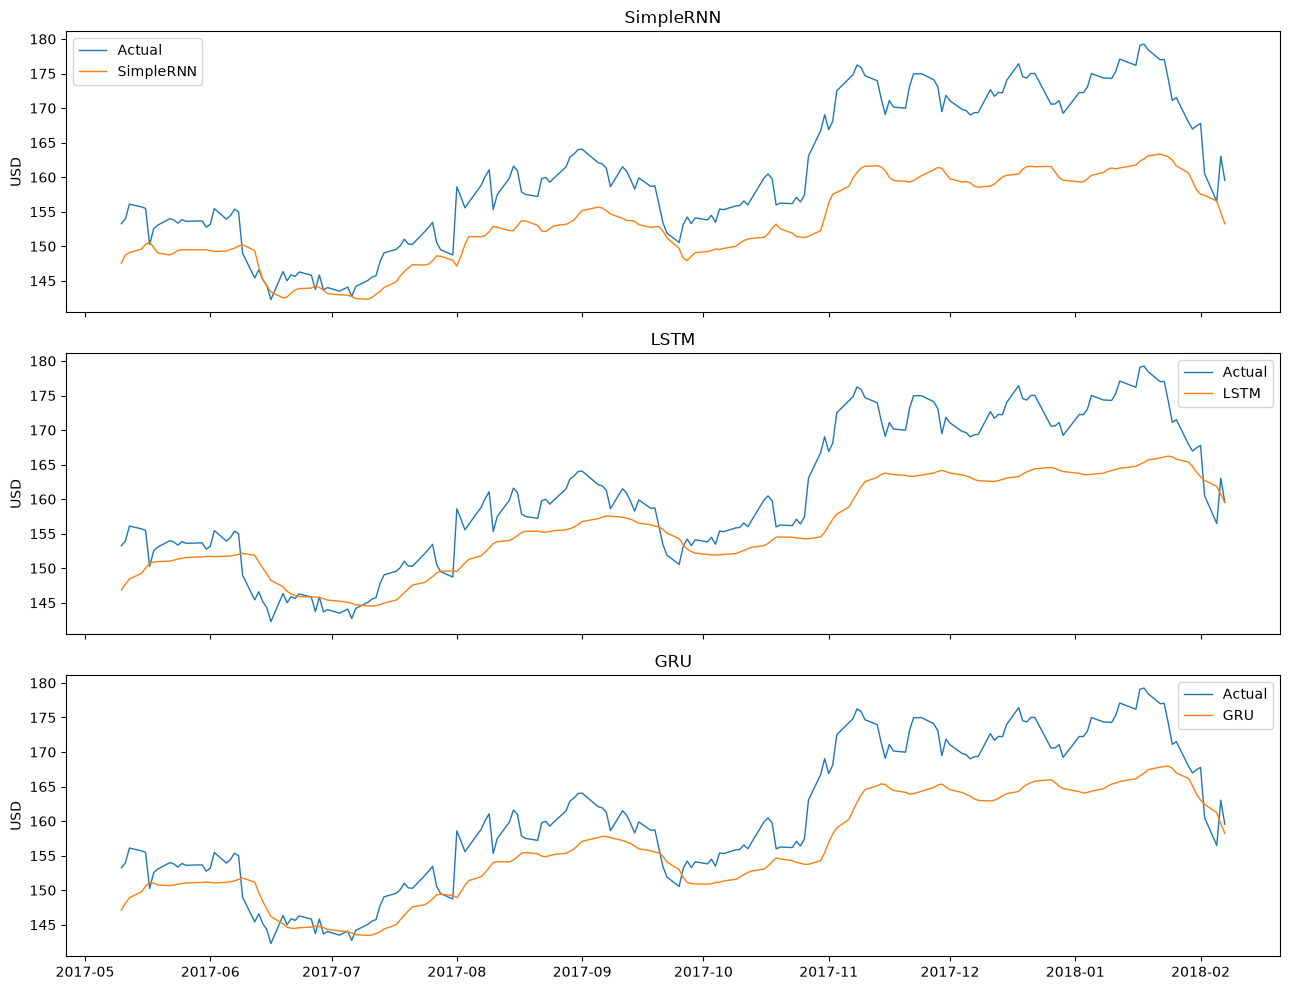

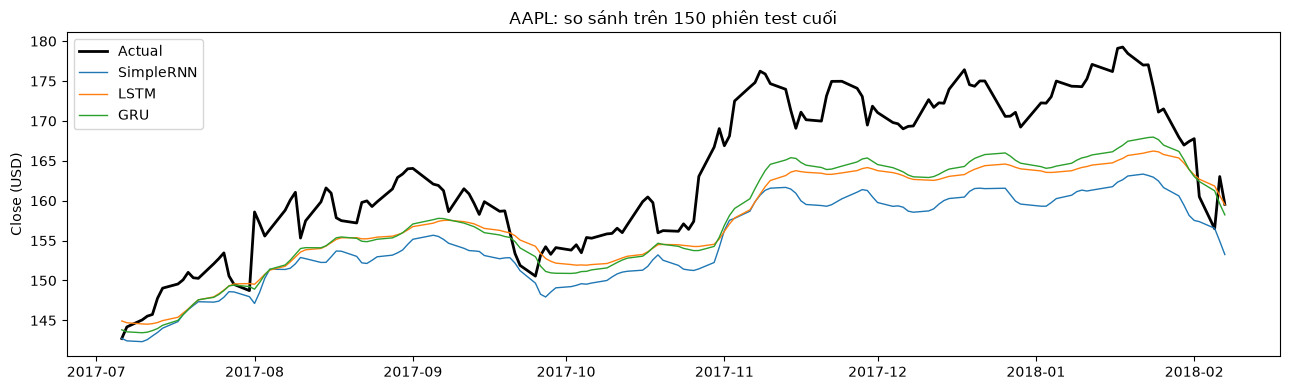

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.plot(test_dates, y_actual, label="Actual", linewidth=1)
    ax.plot(test_dates, y_pred, label=name, linewidth=1)
    ax.set(title=name, ylabel="USD")
    ax.legend()
fig.tight_layout()
plt.show()

last = min(150, len(y_actual))
plt.figure(figsize=(13, 4))
plt.plot(test_dates.iloc[-last:], y_actual[-last:], label="Actual", linewidth=2, color="black")
for name, y_pred in predictions.items():
    plt.plot(test_dates.iloc[-last:], y_pred[-last:], label=name, linewidth=1)
plt.title(f"{STOCK_SYMBOL}: so sánh trên {last} phiên test cuối")
plt.ylabel("Close (USD)")
plt.legend()
plt.tight_layout()
plt.show()

---
## 18. Residual và mô hình tốt nhất

Residual = Actual − Predicted. Đường quanh 0 cho thấy sai số nhỏ; cụm sai số lớn cho thấy giai đoạn mô hình khó theo kịp biến động. Mô hình tốt nhất được xác định bằng RMSE nhỏ nhất trong bảng test, không giả định trước LSTM hay GRU sẽ thắng.

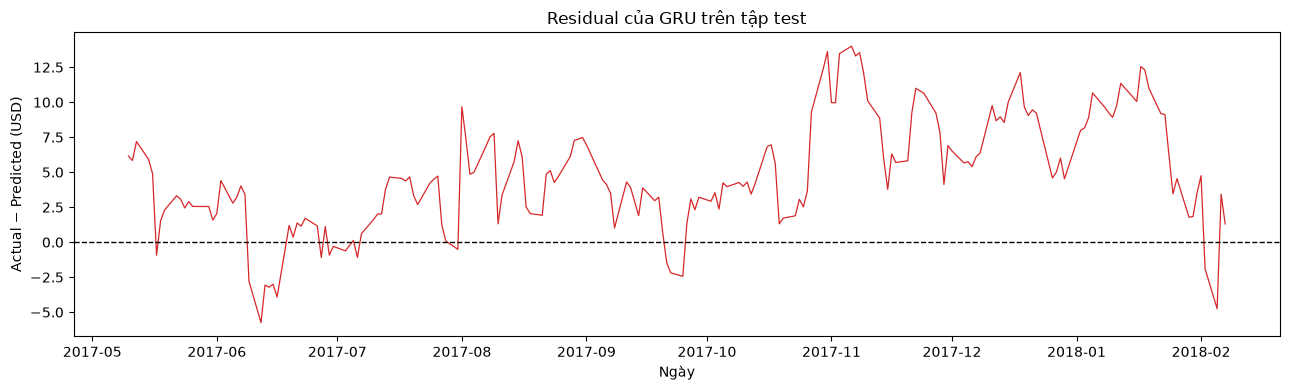

**Best Model: GRU.** RMSE = 6.172 USD, MAE = 5.179 USD, R² = 0.620. Tại epoch tốt nhất, validation/train loss = 0.48. Mô hình này có sai số RMSE thấp nhất trong lần chạy trên chuỗi lịch sử được chọn; nguyên nhân cụ thể cần đọc thêm từ loss curve và residual.

In [18]:
residual = y_actual - predictions[best_name]
plt.figure(figsize=(13, 4))
plt.plot(test_dates, residual, color="tab:red", linewidth=0.9)
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.title(f"Residual của {best_name} trên tập test")
plt.xlabel("Ngày")
plt.ylabel("Actual − Predicted (USD)")
plt.tight_layout()
plt.show()

best_row = results.iloc[0]
best_history = histories[best_name]
best_epoch_index = int(np.argmin(best_history["val"]))
loss_gap = best_history["val"][best_epoch_index] / max(best_history["train"][best_epoch_index], 1e-12)
display(Markdown(
    f"**Best Model: {best_name}.** RMSE = {best_row['RMSE']:.3f} USD, "
    f"MAE = {best_row['MAE']:.3f} USD, R² = {best_row['R2']:.3f}. "
    f"Tại epoch tốt nhất, validation/train loss = {loss_gap:.2f}. "
    "Mô hình này có sai số RMSE thấp nhất trong lần chạy trên chuỗi lịch sử được chọn; "
    "nguyên nhân cụ thể cần đọc thêm từ loss curve và residual."
))

---
## 19. Dự đoán phiên giao dịch kế tiếp

Lấy đúng 60 phiên cuối cùng đã biết làm đầu vào và dùng mô hình tốt nhất. Với dataset này, kết quả là phiên **sau 07/02/2018**, không phải dự báo cho năm hiện tại.

In [19]:
last_window = torch.from_numpy(features_scaled[-SEQUENCE_LENGTH:][None, :, :]).to(device)
best_model.eval()
with torch.no_grad():
    next_scaled = best_model(last_window).cpu().numpy()
next_close = float(target_scaler.inverse_transform(next_scaled)[0, 0])
latest_close = float(stock["close"].iloc[-1])
expected_change = (next_close / latest_close - 1) * 100
trend = "Tăng" if next_close > latest_close else "Giảm" if next_close < latest_close else "Đi ngang"

display(pd.DataFrame([{
    "Mã": STOCK_SYMBOL,
    "Phiên dữ liệu cuối": stock["date"].iloc[-1].date(),
    "Close gần nhất (USD)": latest_close,
    "Close dự đoán phiên tiếp (USD)": next_close,
    "Thay đổi dự kiến (%)": expected_change,
    "Xu hướng": trend,
}]).round(2))
display(Markdown("*Kết quả chỉ nhằm minh họa mô hình học máy, không phải khuyến nghị đầu tư.*"))

,Mã,Phiên dữ liệu cuối,Close gần nhất (USD),Close dự đoán phiên tiếp (USD),Thay đổi dự kiến (%),Xu hướng
0,AAPL,2018-02-07,159.54,157.37,-1.36,Giảm


*Kết quả chỉ nhằm minh họa mô hình học máy, không phải khuyến nghị đầu tư.*

---
## 20. Lưu mô hình và scaler

Lưu trọng số, kiến trúc và metadata trong `stock_best_model.pth`. Lưu riêng feature scaler và target scaler trong `stock_scaler.pkl` để suy luận sau này luôn dùng đúng phép chuẩn hóa đã fit trên train.

In [20]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
model_path = ARTIFACT_DIR / "stock_best_model.pth"
scaler_path = ARTIFACT_DIR / "stock_scaler.pkl"
torch.save({
    "model_name": best_name,
    "state_dict": best_model.cpu().state_dict(),
    "symbol": STOCK_SYMBOL,
    "features": FEATURES,
    "sequence_length": SEQUENCE_LENGTH,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "last_data_date": str(stock["date"].iloc[-1].date()),
}, model_path)
joblib.dump({"feature_scaler": feature_scaler, "target_scaler": target_scaler}, scaler_path)
print(f"Đã lưu {model_path} và {scaler_path}")

Đã lưu artifacts\stock_best_model.pth và artifacts\stock_scaler.pkl


---
## 21. Thử nhanh mã cổ phiếu khác

Dataset cũng có `MSFT`, `GOOGL`, `AMZN`. Đổi `STOCK_SYMBOL` ở ô **01** rồi chọn **Restart & Run All** để toàn bộ bước lọc, chuẩn hóa, huấn luyện, đánh giá và lưu mô hình dùng mã mới. Mỗi lần chỉ huấn luyện một mã, tránh dùng nhầm scaler của mã trước.

In [21]:
for symbol in ["AAPL", "MSFT", "GOOGL", "AMZN"]:
    print(f"{symbol}: {int((raw['Name'] == symbol).sum()):,} phiên trong CSV")

AAPL: 1,259 phiên trong CSV
MSFT: 1,259 phiên trong CSV
GOOGL: 1,259 phiên trong CSV
AMZN: 1,259 phiên trong CSV


---
## 22. Kết luận

Bảng và đoạn tổng kết dưới đây được tạo từ kết quả vừa chạy, nên khi đổi mã cổ phiếu, nội dung sẽ cập nhật theo. So sánh RNN, LSTM, GRU chỉ phản ánh một lát cắt thời gian và một lần chia train/validation/test; giá lịch sử không chứa tin tức, sự kiện doanh nghiệp hay biến động vĩ mô. Dataset chưa điều chỉnh đầy đủ cho mọi sự kiện như chia tách cổ phiếu, vì vậy không nên diễn giải kết quả như hiệu quả giao dịch thực tế.

In [22]:
summary_table = results[["Model", "MAE", "RMSE", "R2", "MAPE (%)", "Training Time (s)"]].copy()
display(summary_table.round(3))

model_notes = {
    "SimpleRNN": "Cấu trúc hồi quy cơ bản phù hợp nhất trên lát cắt test này, dù có thể khó giữ thông tin qua chuỗi dài.",
    "LSTM": "Cơ chế ô nhớ và các cổng cho sai số thấp nhất trên lát cắt test này.",
    "GRU": "Cơ chế cổng gọn hơn LSTM cho sai số thấp nhất trên lát cắt test này.",
}
display(Markdown(
    f"**Dataset:** `all_stocks_5yr.csv` (Kaggle S&P 500).  \n"
    f"**Mã:** {STOCK_SYMBOL}; **khoảng thời gian:** {stock['date'].min():%d/%m/%Y}–{stock['date'].max():%d/%m/%Y}.  \n"
    f"**Feature:** {', '.join(FEATURES)}; **cửa sổ:** {SEQUENCE_LENGTH} phiên.  \n"
    f"**Số mẫu train/validation/test:** {len(X_train)}/{len(X_val)}/{len(X_test)}.  \n"
    f"**RMSE:** SimpleRNN {results.set_index('Model').loc['SimpleRNN', 'RMSE']:.3f}; "
    f"LSTM {results.set_index('Model').loc['LSTM', 'RMSE']:.3f}; "
    f"GRU {results.set_index('Model').loc['GRU', 'RMSE']:.3f} USD.  \n"
    f"**Mô hình tốt nhất theo RMSE:** {best_name}. {model_notes[best_name]} "
    "Đọc thêm chênh lệch loss và residual trước khi kết luận về nguyên nhân.  \n"
    "**Hạn chế:** Chỉ dùng OHLCV lịch sử, không có tin tức, dữ liệu cơ bản hay bối cảnh thị trường; "
    "dữ liệu dừng ở năm 2018 và không phản ánh giá hiện tại."
))

,Model,MAE,RMSE,R2,MAPE (%),Training Time (s)
0,GRU,5.179,6.172,0.620,3.137,6.427
1,LSTM,5.456,6.676,0.555,3.293,4.027
2,SimpleRNN,7.353,8.581,0.265,4.439,6.100


**Dataset:** `all_stocks_5yr.csv` (Kaggle S&P 500).  
**Mã:** AAPL; **khoảng thời gian:** 08/02/2013–07/02/2018.  
**Feature:** open, high, low, close, volume; **cửa sổ:** 60 phiên.  
**Số mẫu train/validation/test:** 821/189/189.  
**RMSE:** SimpleRNN 8.581; LSTM 6.676; GRU 6.172 USD.  
**Mô hình tốt nhất theo RMSE:** GRU. Cơ chế cổng gọn hơn LSTM cho sai số thấp nhất trên lát cắt test này. Đọc thêm chênh lệch loss và residual trước khi kết luận về nguyên nhân.  
**Hạn chế:** Chỉ dùng OHLCV lịch sử, không có tin tức, dữ liệu cơ bản hay bối cảnh thị trường; dữ liệu dừng ở năm 2018 và không phản ánh giá hiện tại.